In [ ]:
pip install pandas scikit-learn matplotlib seaborn transformers datasets

In [ ]:
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import os
import datetime
from tqdm import tqdm

In [ ]:
def load_emotion_file(path):
    data = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if ";" in line:
                text, label = line.strip().split(";", 1)
                data.append((text.strip(), label.strip()))
    return pd.DataFrame(data, columns=["text", "label"])

df = load_emotion_file("train.txt")  # Make sure this file is in your folder
print(f"Total entries: {len(df)}")
print(df.head())

Total entries: 16000
                                                text    label
0                            i didnt feel humiliated  sadness
1  i can go from feeling so hopeless to so damned...  sadness
2   im grabbing a minute to post i feel greedy wrong    anger
3  i am ever feeling nostalgic about the fireplac...     love
4                               i am feeling grouchy    anger


In [ ]:
model_name = "j-hartmann/emotion-english-distilroberta-base"  # faster than BERT
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Use GPU if available
device = 0 if torch.cuda.is_available() else -1
emotion_classifier = pipeline("text-classification", model=model, tokenizer=tokenizer, device=device)


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/329M [00:00<?, ?B/s]

Device set to use cpu


In [ ]:
def batch_predict(texts, batch_size=32):
    preds, confs = [], []
    for i in tqdm(range(0, len(texts), batch_size)):
        batch = texts[i:i+batch_size]
        results = emotion_classifier(batch)
        for r in results:
            preds.append(r['label'])
            confs.append(round(r['score'], 3))
    return preds, confs


In [ ]:
cache_file = "predicted_emotions.csv"

if os.path.exists(cache_file):
    df = pd.read_csv(cache_file)
    print("✅ Loaded cached predictions.")
else:
    df['predicted'], df['confidence'] = batch_predict(df['text'].tolist())
    df.to_csv(cache_file, index=False)
    print("✅ Predictions completed and cached.")


✅ Loaded cached predictions.



📊 Classification Report:


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_

              precision    recall  f1-score   support

       anger       0.85      0.93      0.89      2159
     disgust       0.00      0.00      0.00         0
        fear       0.86      0.91      0.88      1937
         joy       0.82      0.93      0.87      5362
        love       0.00      0.00      0.00      1304
     neutral       0.00      0.00      0.00         0
     sadness       0.91      0.92      0.91      4666
    surprise       0.72      0.91      0.80       572

    accuracy                           0.85     16000
   macro avg       0.52      0.58      0.55     16000
weighted avg       0.78      0.85      0.82     16000



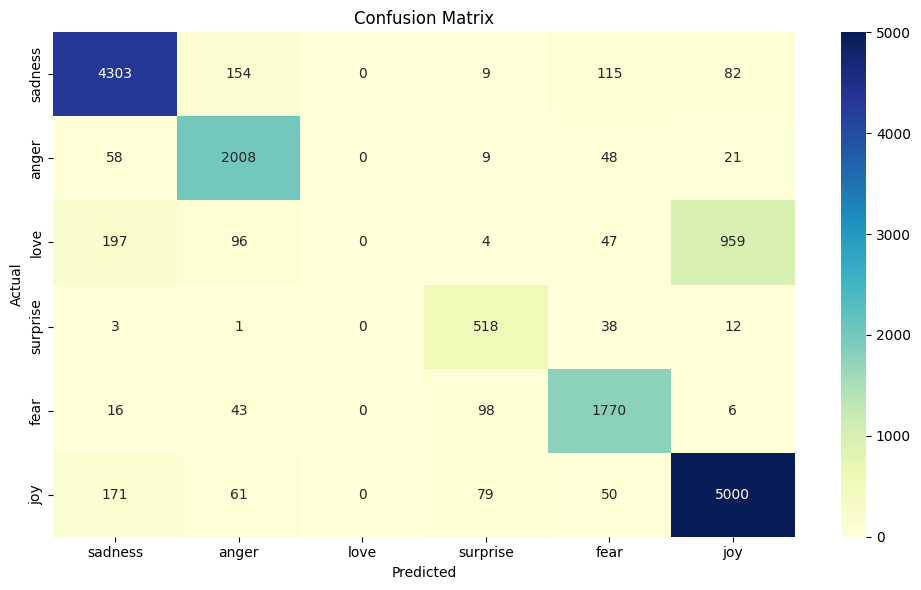

In [ ]:
print("\n📊 Classification Report:")
print(classification_report(df['label'], df['predicted']))

labels = df['label'].unique()
cm = confusion_matrix(df['label'], df['predicted'], labels=labels)

plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
def log_mood_entry(journal_text, log_file="mood_log.csv"):
    result = emotion_classifier(journal_text)[0]
    mood = result['label']
    confidence = round(result['score'], 3)
    today = datetime.date.today().isoformat()

    new_entry = {
        "date": today,
        "journal": journal_text,
        "predicted_mood": mood,
        "confidence": confidence
    }

    if os.path.exists(log_file):
        df_log = pd.read_csv(log_file)
        df_log = pd.concat([df_log, pd.DataFrame([new_entry])], ignore_index=True)
    else:
        df_log = pd.DataFrame([new_entry])

    df_log.to_csv(log_file, index=False)
    print(f"✅ Logged: {today} | Mood: {mood} | Confidence: {confidence}")


In [ ]:
journal_text = input("📝 How was your day?\n")
log_mood_entry(journal_text)

📝 How was your day?
i am suffering from fever. but i could not sleep.
✅ Logged: 2025-07-28 | Mood: sadness | Confidence: 0.987


/tmp/ipython-input-33-1056247199.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_log, x="predicted_mood", order=df_log["predicted_mood"].value_counts().index, palette="Set2")
/tmp/ipython-input-33-1056247199.py:11: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


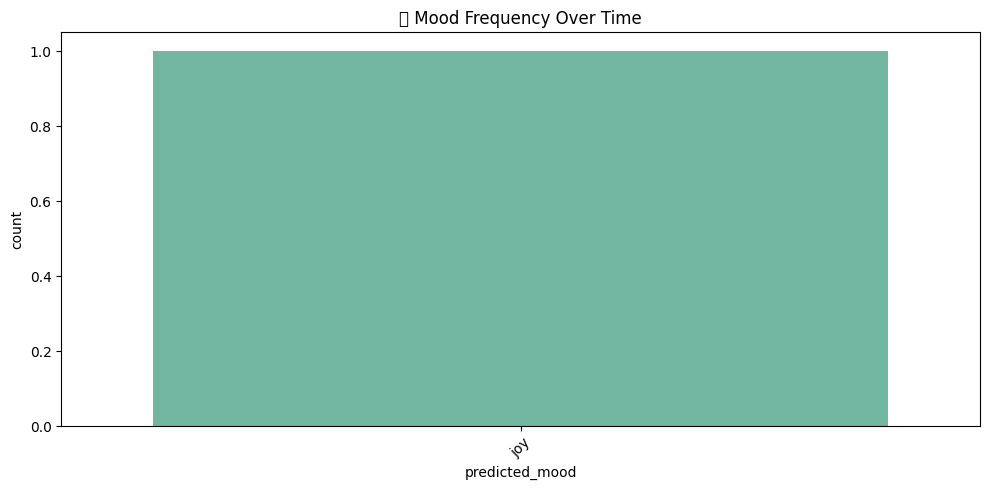

In [ ]:
def plot_mood_trends(log_file="mood_log.csv"):
    if not os.path.exists(log_file):
        print("❌ No mood logs yet.")
        return

    df_log = pd.read_csv(log_file)
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df_log, x="predicted_mood", order=df_log["predicted_mood"].value_counts().index, palette="Set2")
    plt.title("🧠 Mood Frequency Over Time")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_mood_trends()